# Example notebook

In [11]:
%load_ext autoreload
%autoreload 2

import anndata as ad
from seq_lumen import SeqLumen
from anndata.acc import A
import numpy as np
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
adata = ad.read_h5ad(
    "/data1/peerd/roses3/basal_ablation/data/processed/xenium/compiled_adata/BA_processed_segger_pub_20260621.h5ad"
)
sample_id = adata[adata.obs["condition"] == "control"].obs["sample_id"].cat.categories[6]
adata = adata[adata.obs["sample_id"] == sample_id]

In [13]:
adata.obs["is_epithelial"] = (adata.obs["cell_annotation_coarse"] == "Normal Epithelial") | (
    adata.obs["cell_annotation_coarse"] == "Cancer_epithelial"
)

/tmp/ipykernel_2438658/221784893.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["is_epithelial"] = (adata.obs["cell_annotation_coarse"] == "Normal Epithelial") | (


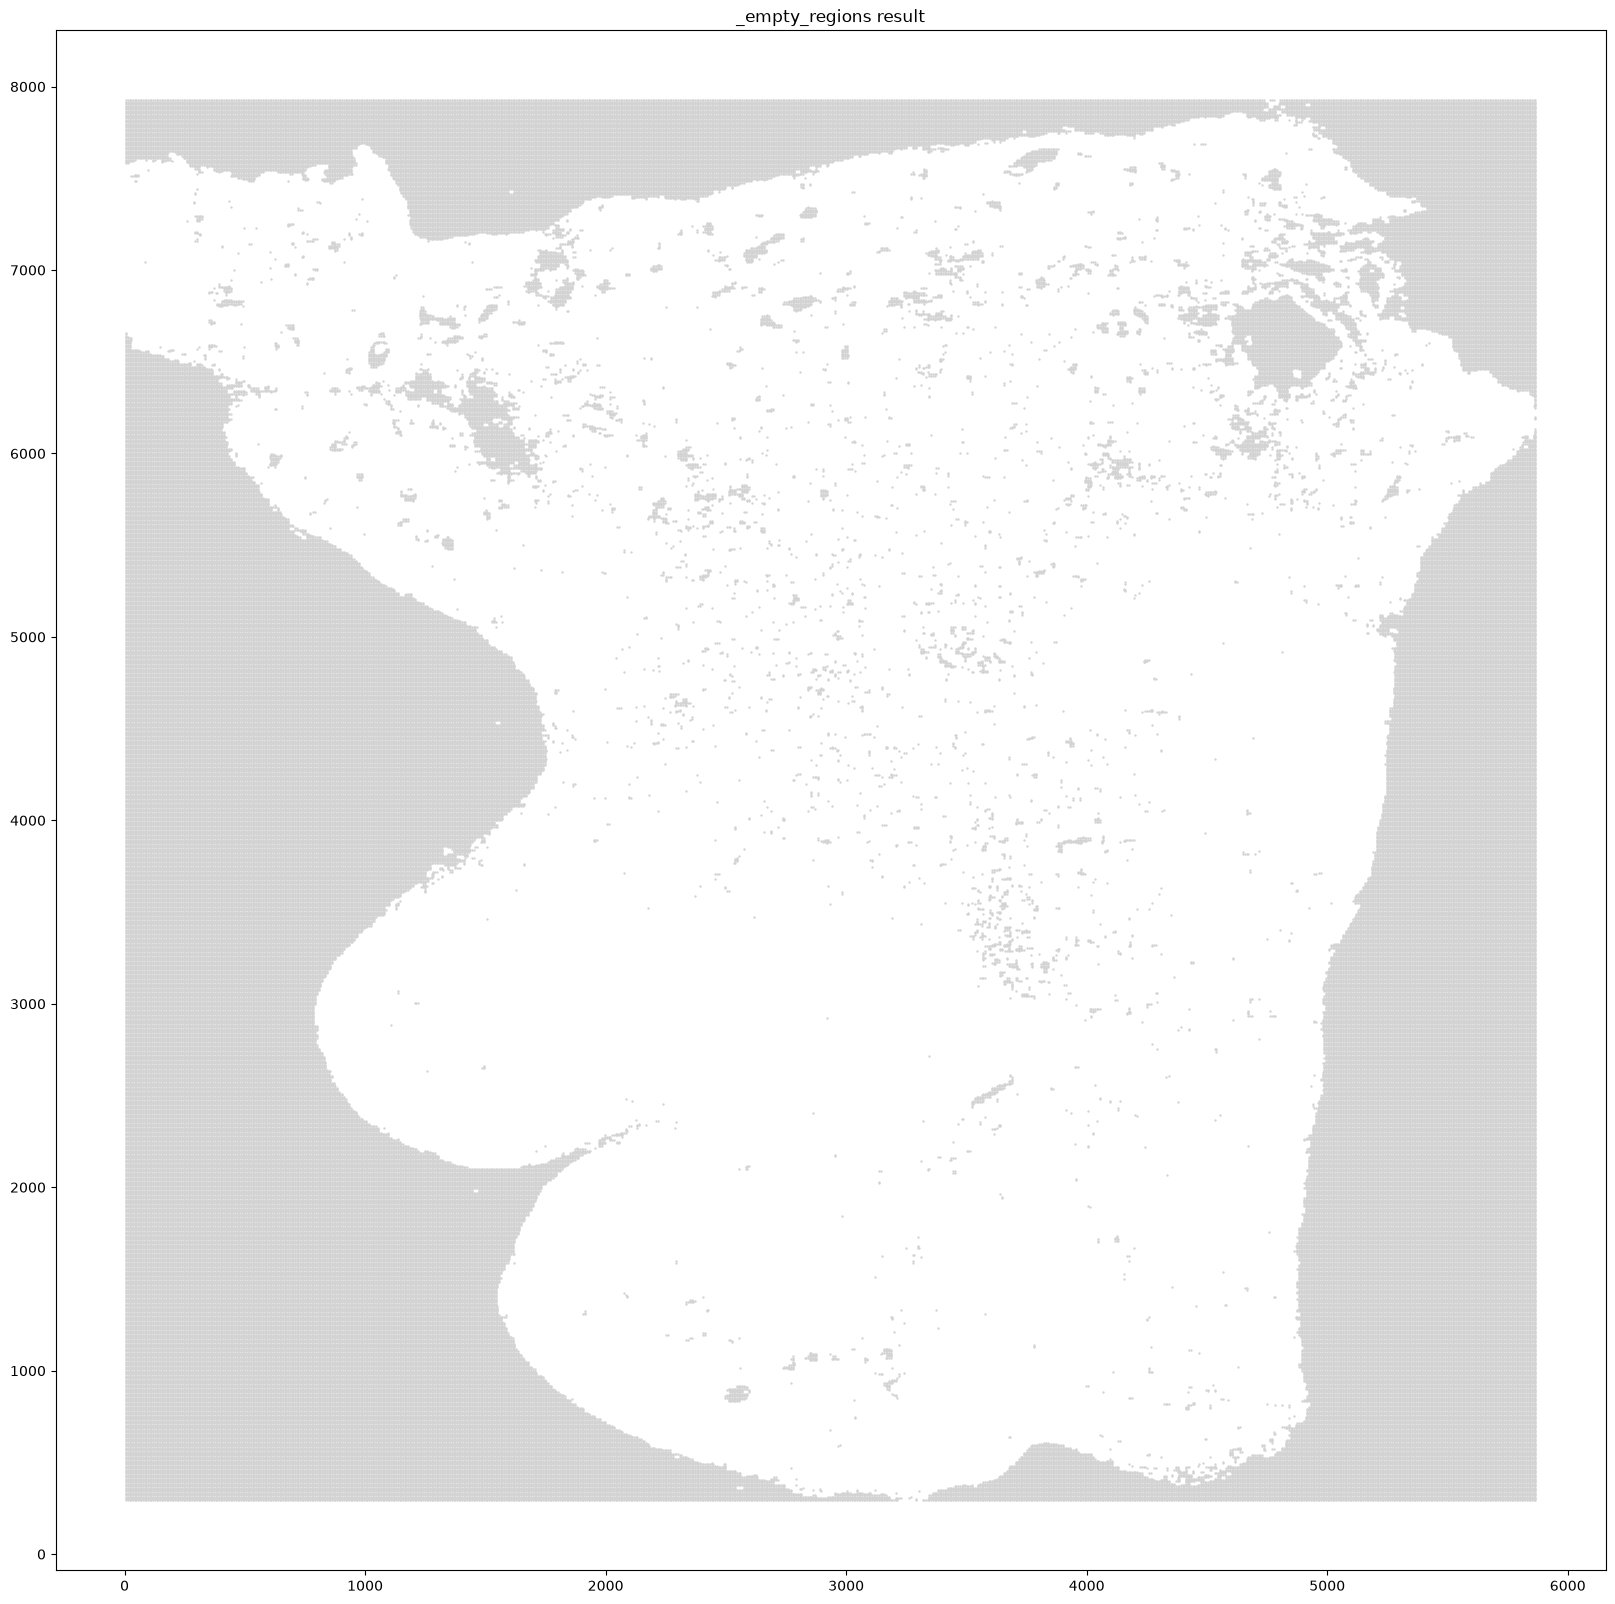

In [14]:
sl = SeqLumen(n_iterations=2, interpoint_distance=7, blurring_bandwdith=3, min_density=0.01, min_cells_per_lesion=5)
border_ids = adata[A.obs["is_epithelial"]]
centroids = adata[A.obsm["X_spatial"]]
empty_region_coords = sl._empty_regions(centroids)
plt.figure(figsize=[20, 20])
plt.scatter(empty_region_coords[:, 0], empty_region_coords[:, 1], s=0.5, c="lightgray")
plt.title("_empty_regions result")
plt.show()

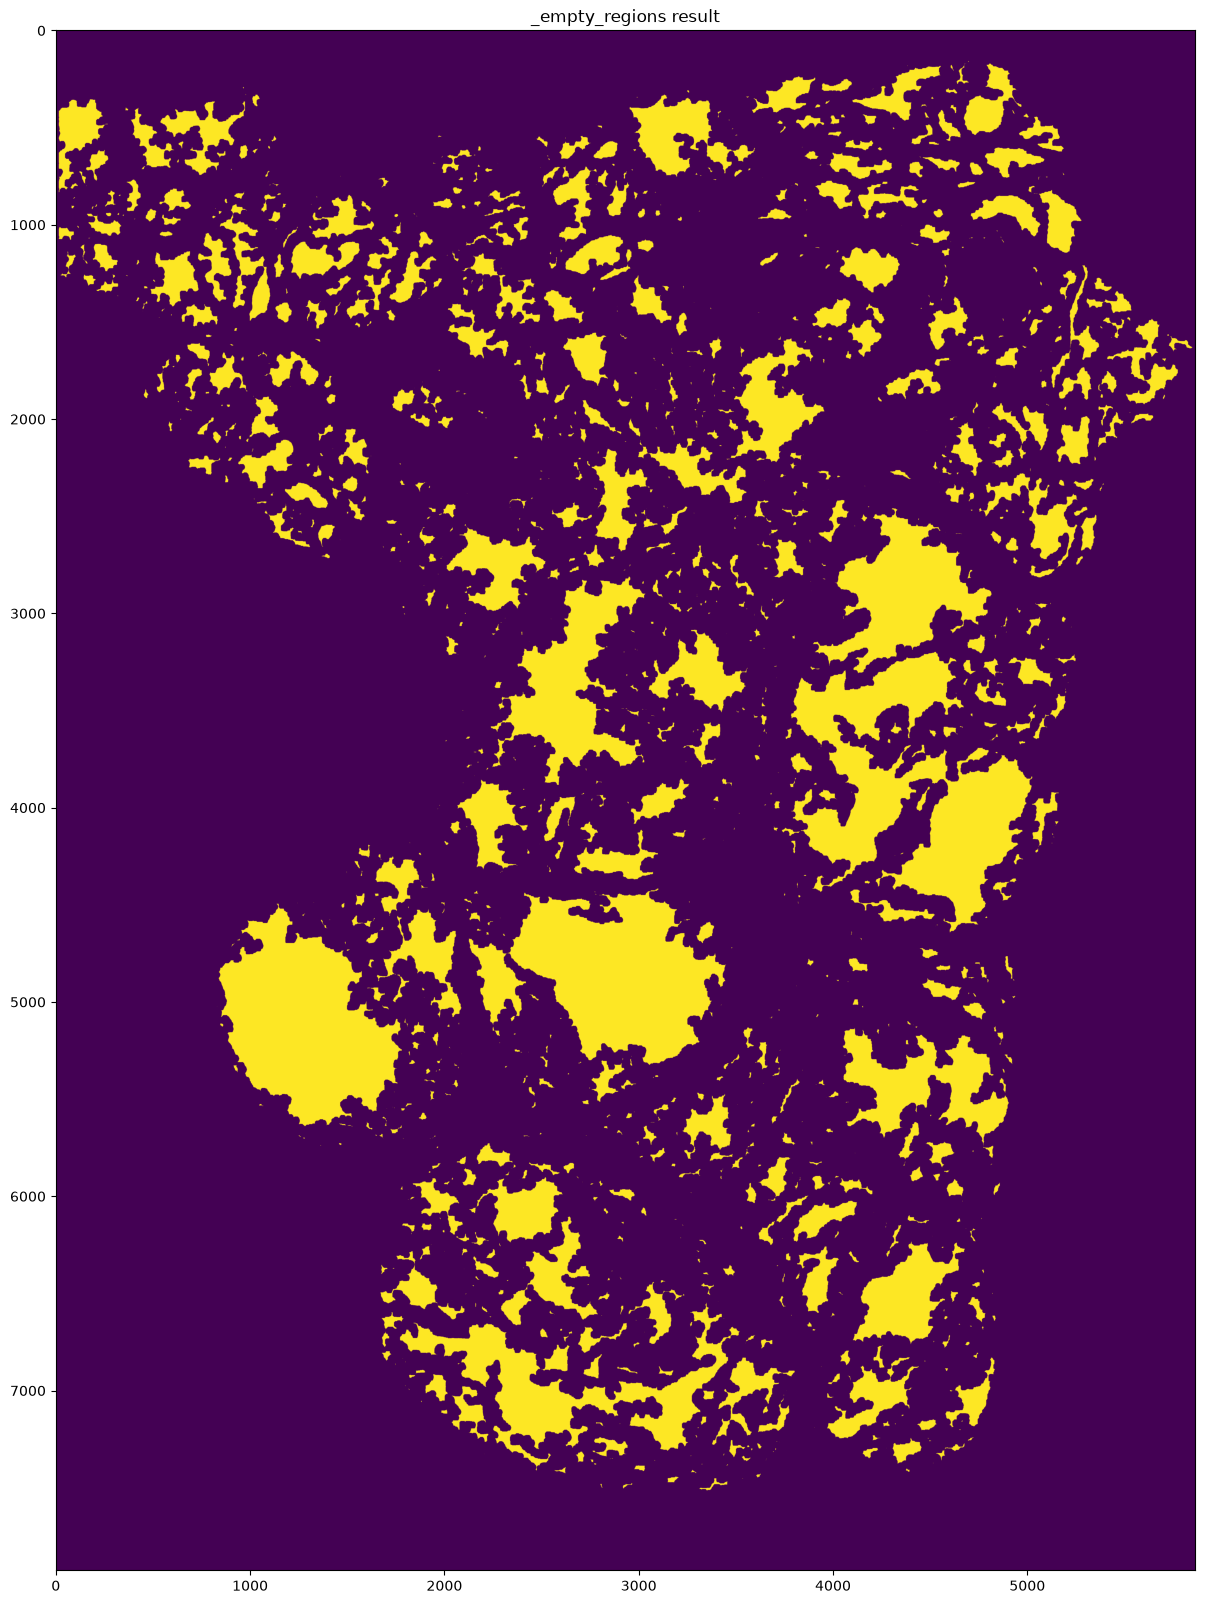

In [15]:
rasterized = np.zeros([int(np.max(centroids[:, 0])), int(np.max(centroids[:, 1]))])
border_centroids = centroids[border_ids, :].copy()
rasterized[
    border_centroids[:, 0].astype(np.uint32) - 1,
    border_centroids[:, 1].astype(np.uint32) - 1,
] = 1
holes = sl._get_rasterized_holes(rasterized)
plt.figure(figsize=[20, 20])
plt.imshow(holes.T[::-1])
plt.title("_empty_regions result")
plt.show()

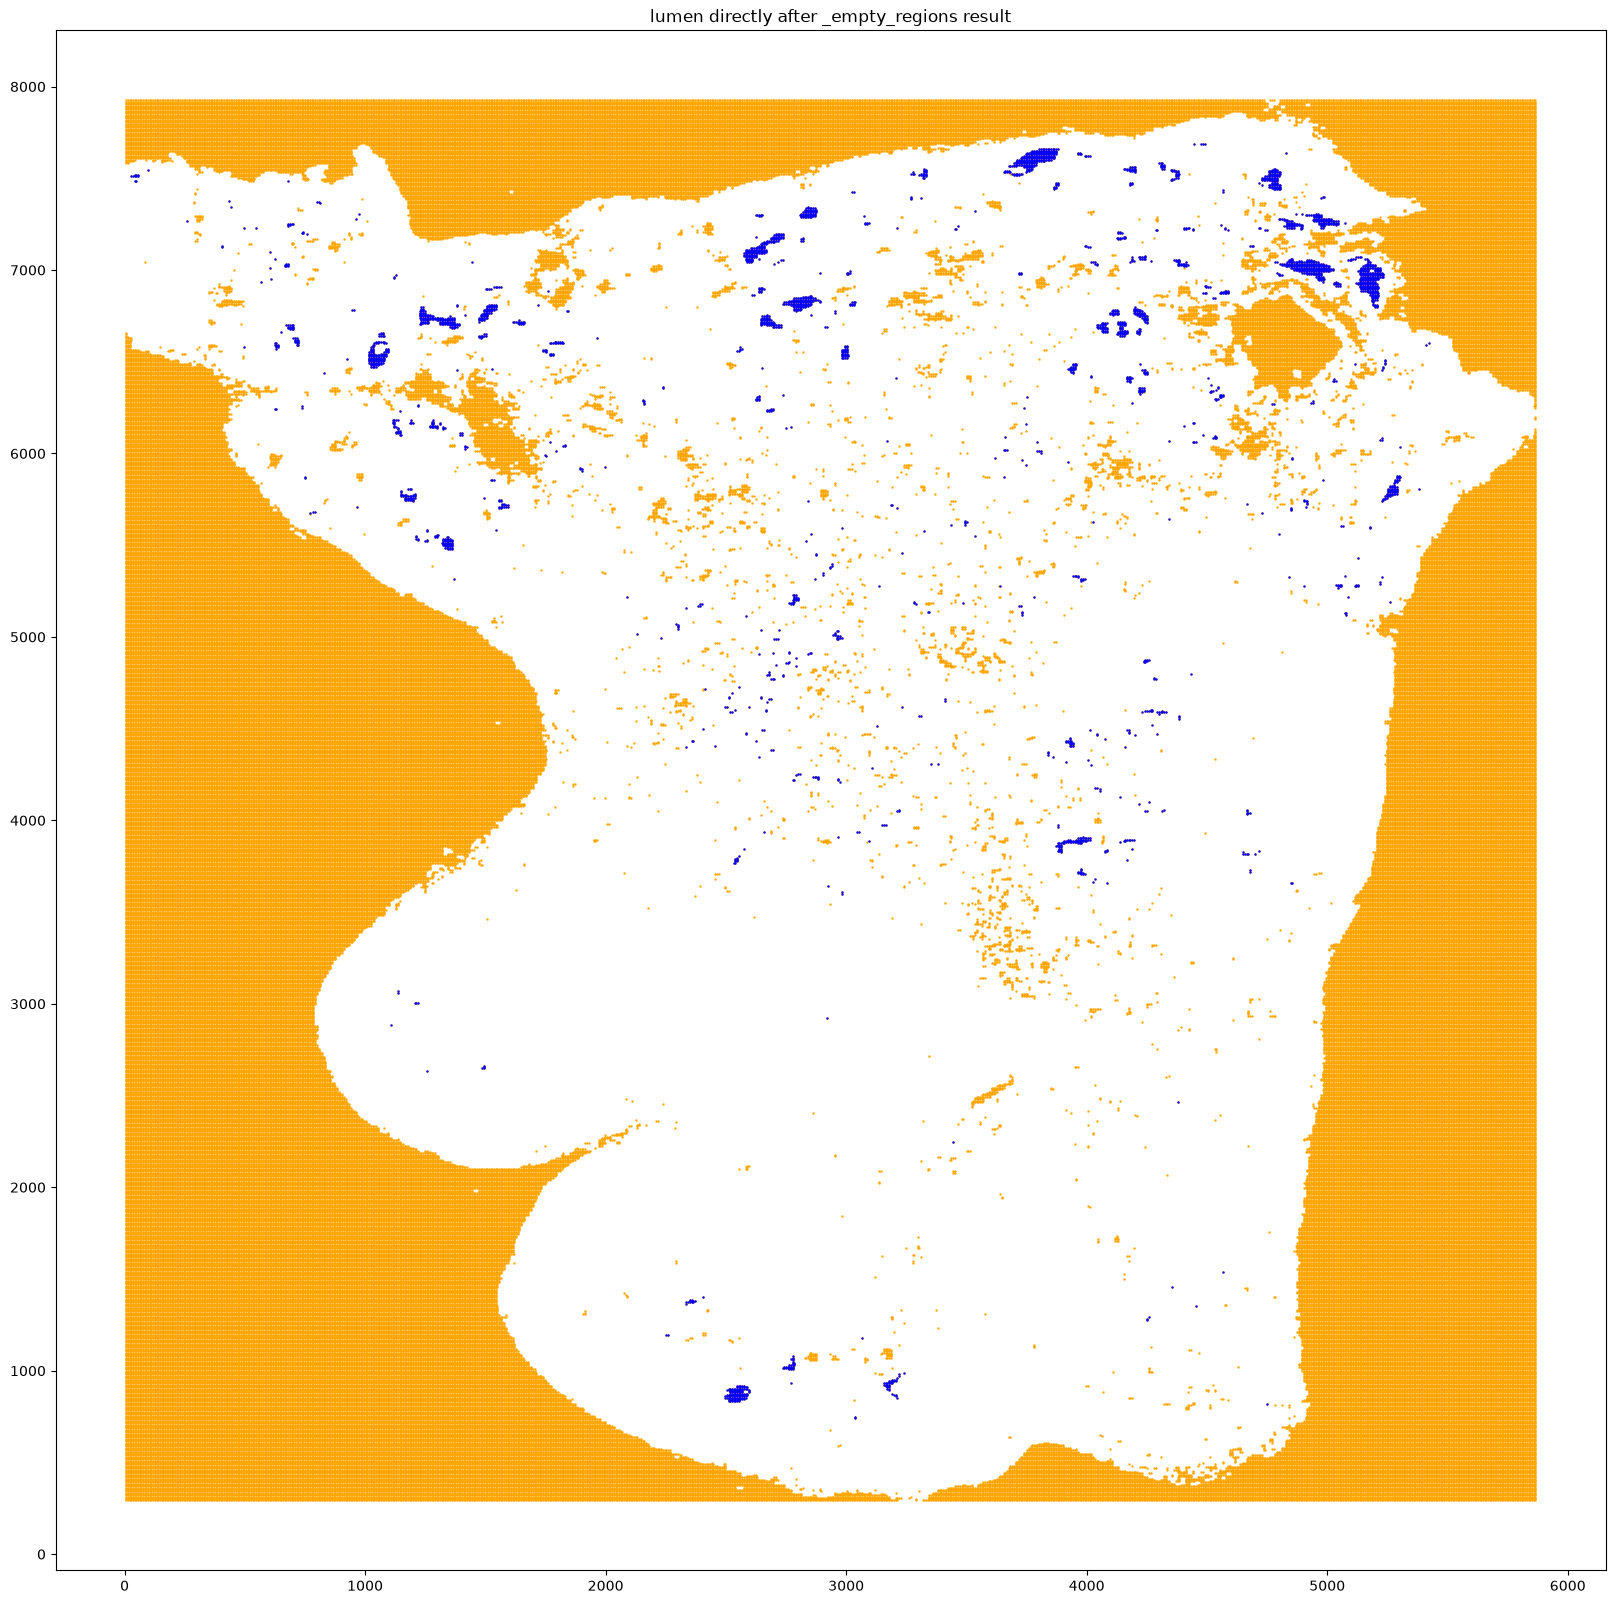

In [16]:
masked_value = holes[empty_region_coords[:, 0].astype(np.uint32), empty_region_coords[:, 1].astype(np.uint32)]
lumen = empty_region_coords[masked_value == 1, :]
plt.figure(figsize=[20, 20])
plt.scatter(empty_region_coords[:, 0], empty_region_coords[:, 1], c="orange", s=0.5)
plt.scatter(lumen[:, 0], lumen[:, 1], c="blue", s=0.5)
plt.title("lumen directly after _empty_regions result")
plt.show()

100%|██████████| 5/5 [00:00<00:00, 11.38it/s]


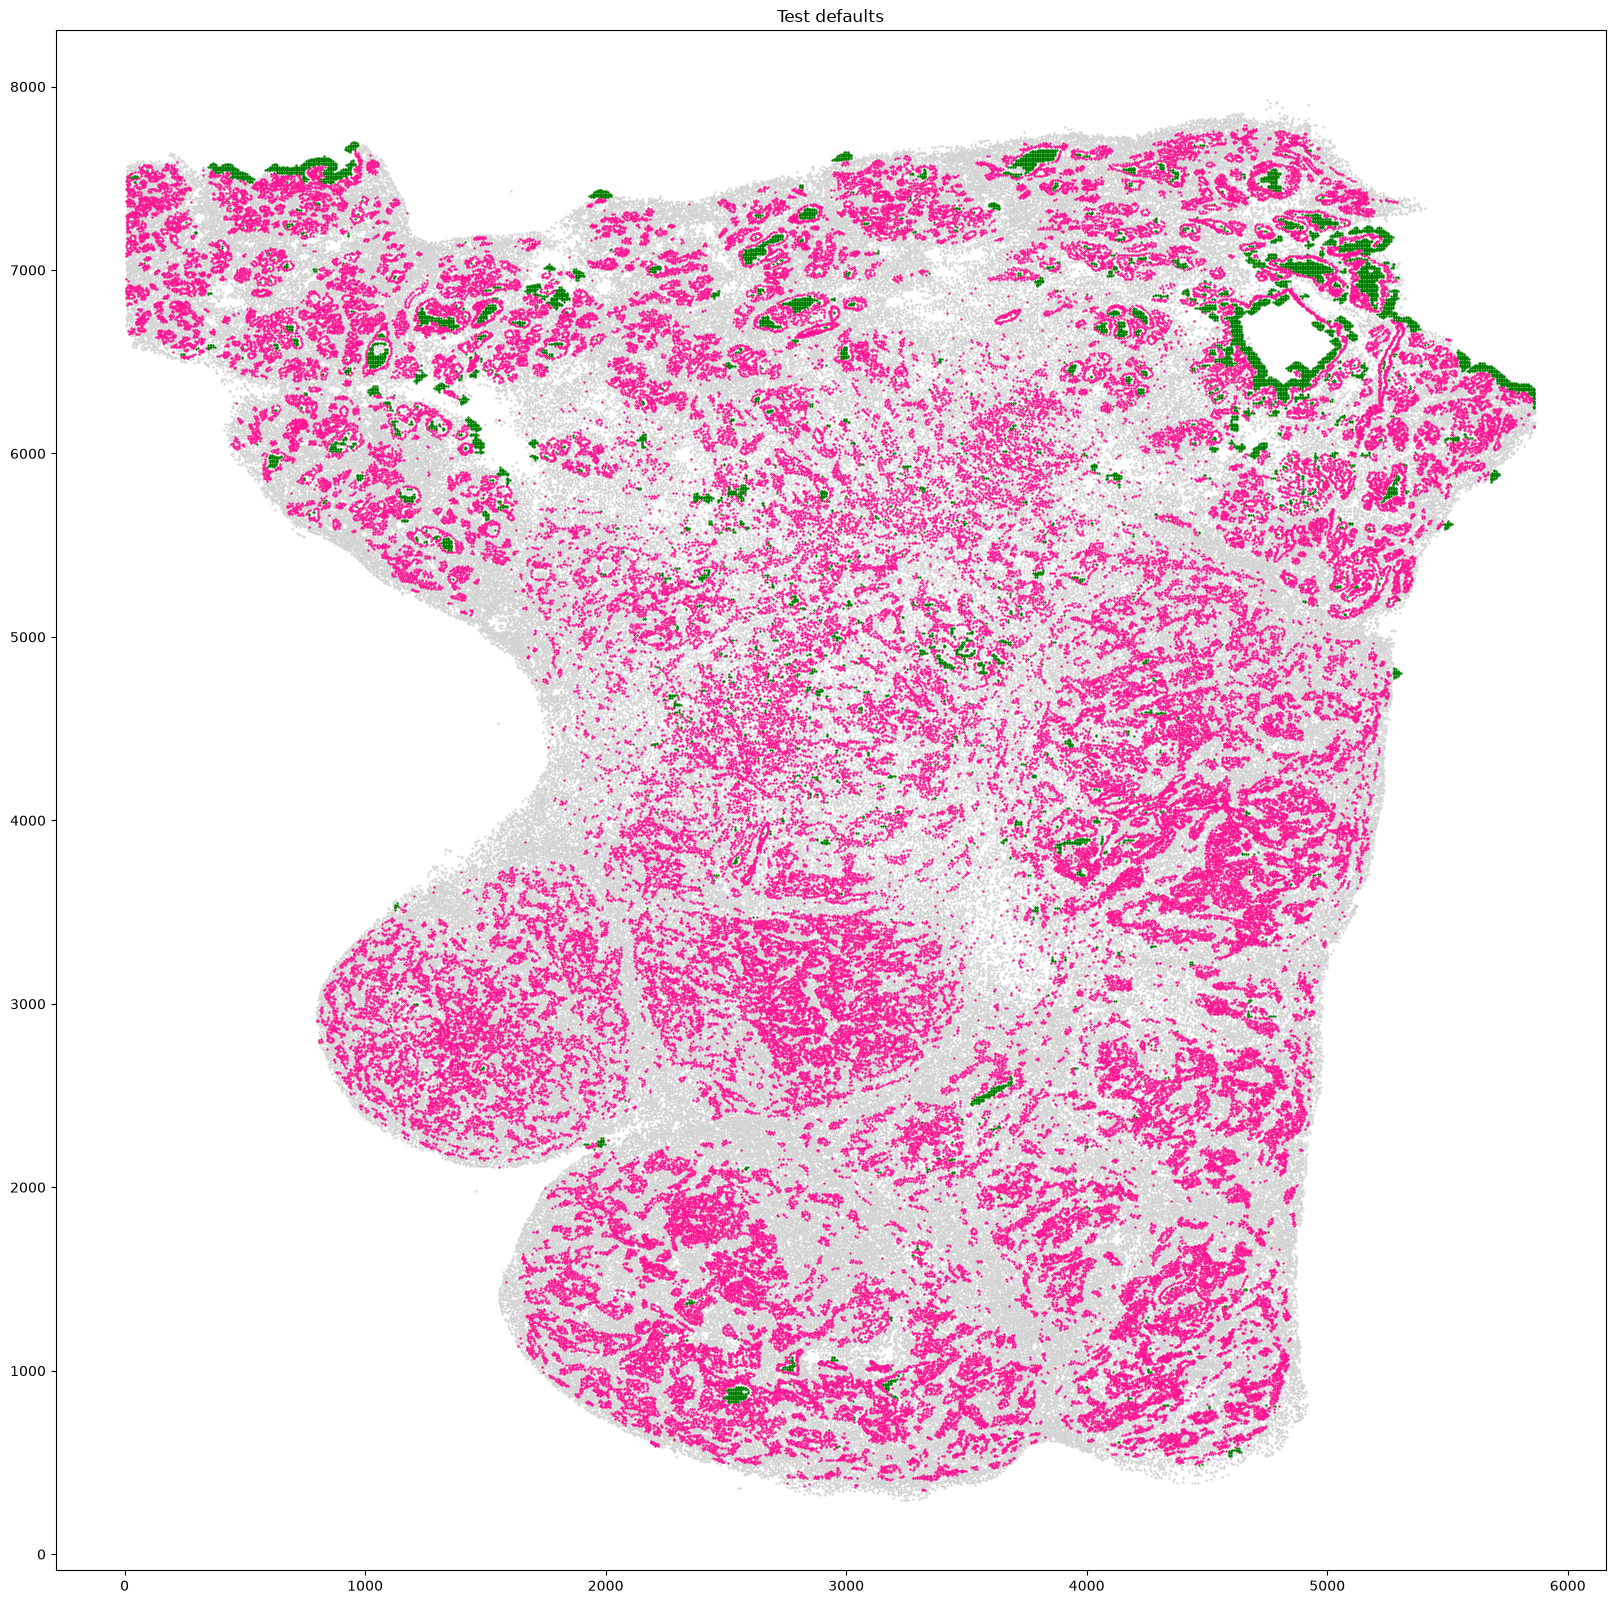

In [17]:
lumen = sl.lumen_coords(adata, centroids_acc=A.obsm["X_spatial"], border_acc=A.obs["is_epithelial"])
plt.figure(figsize=[20, 20])
plt.scatter(centroids[:, 0], centroids[:, 1], s=0.5, c="lightgray")
plt.scatter(border_centroids[:, 0], border_centroids[:, 1], s=0.5, c="deeppink")
plt.scatter(lumen[:, 0], lumen[:, 1], s=0.5, c="green")
plt.title("Test defaults")
plt.show()

In [ ]:
lumen = SeqLumen().lumen_coords(adata, centroids_acc=A.obsm["X_spatial"], border_acc=A.obs["is_epithelial"])
plt.figure(figsize=[20, 20])
plt.scatter(centroids[:, 0], centroids[:, 1], s=0.5, c="lightgray")
plt.scatter(border_centroids[:, 0], border_centroids[:, 1], s=0.5, c="deeppink")
plt.scatter(lumen[:, 0], lumen[:, 1], s=0.5, c="green")
plt.title("Test defaults")
plt.show()

100%|██████████| 5/5 [00:00<00:00,  7.41it/s]


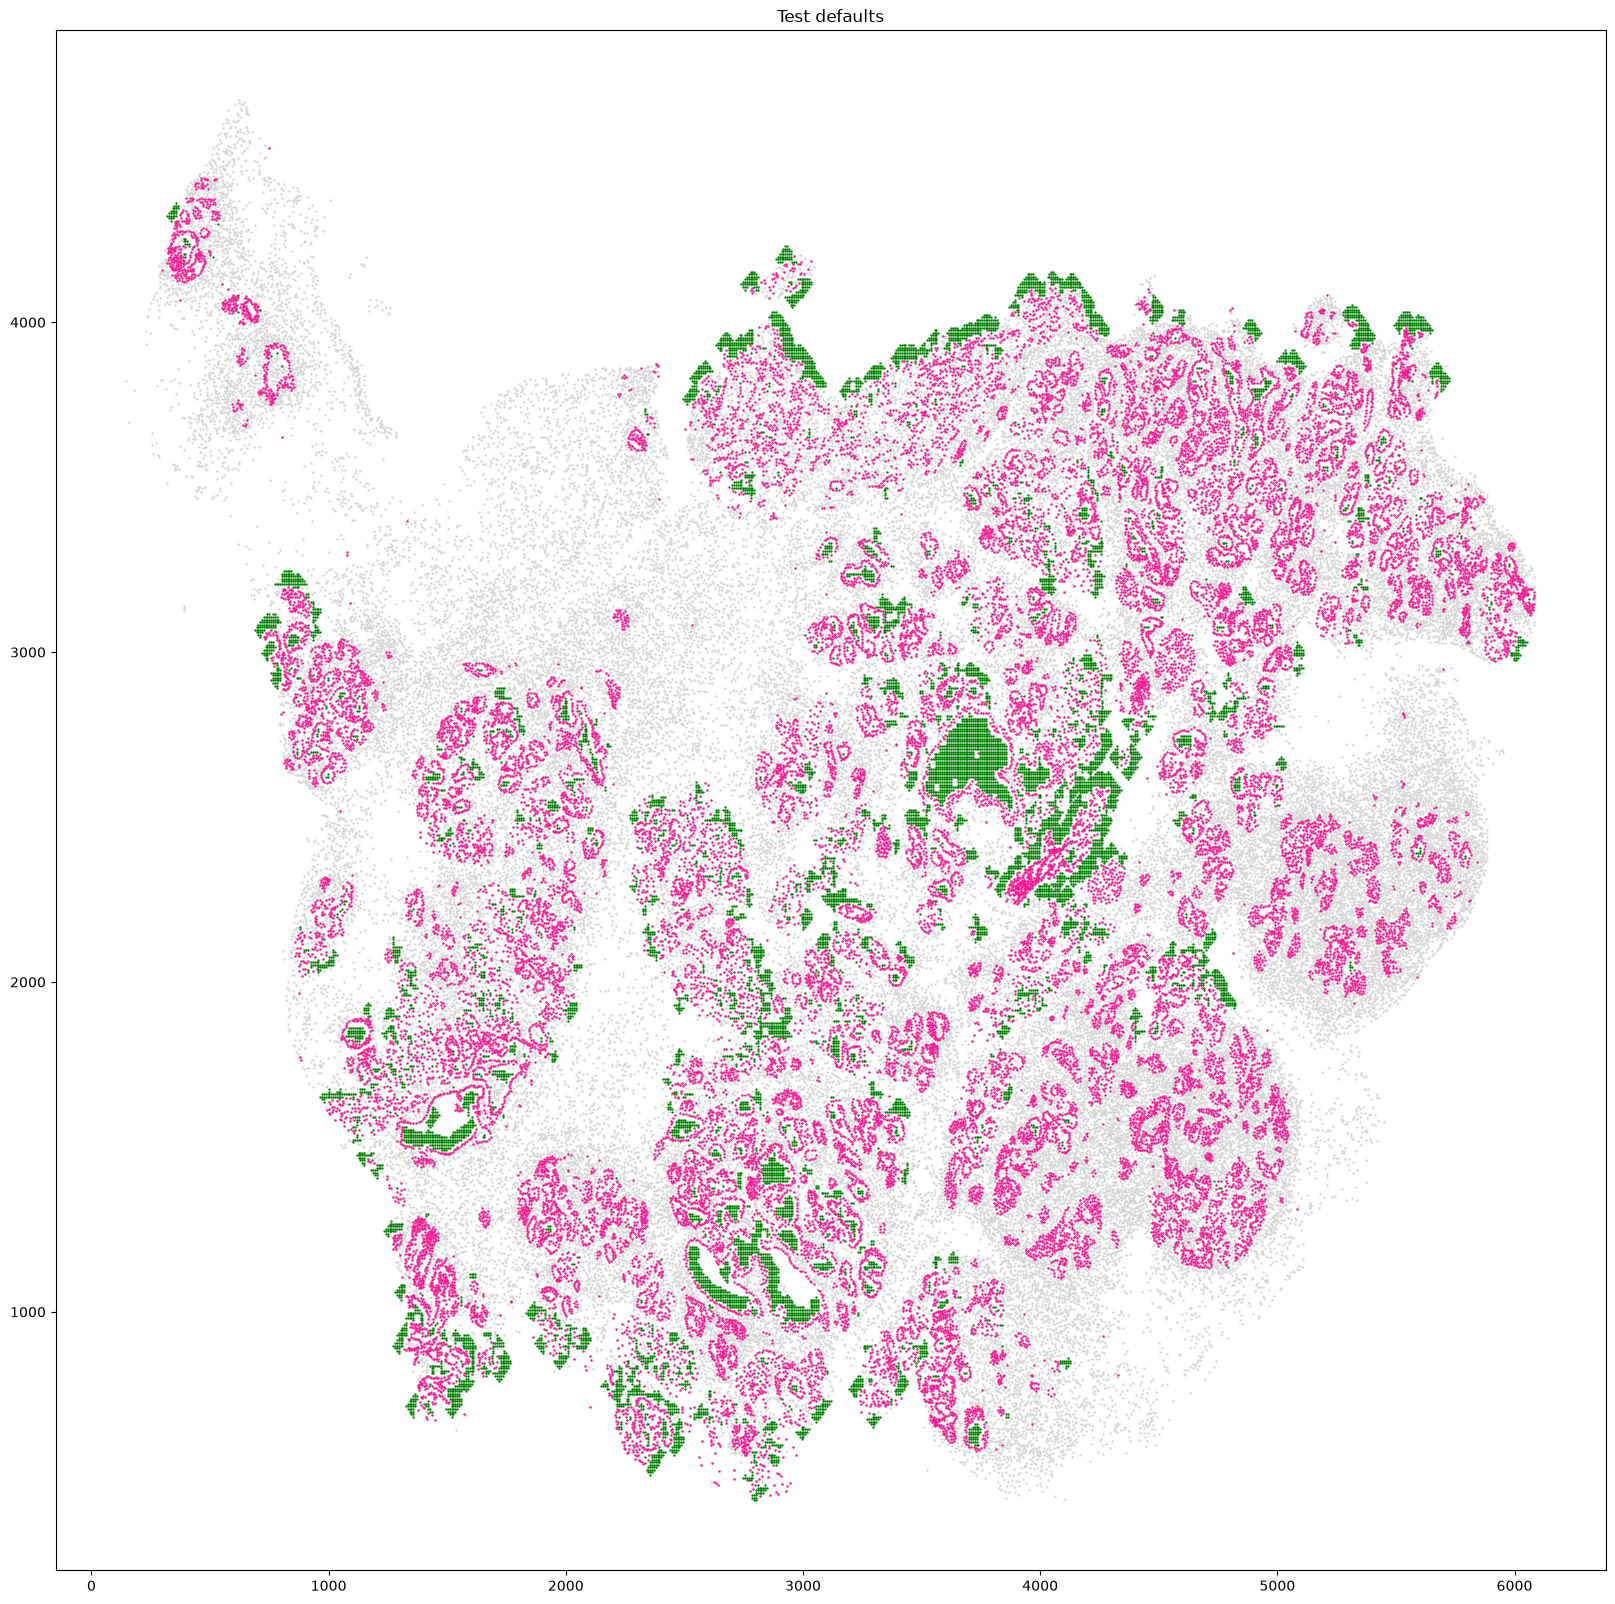

In [ ]:
sl = SeqLumen.from_centroids(
    adata,
    centroids_acc=A.obsm["X_spatial"],
    sample_acc=A.obs["sample_id"],
)
lumen = sl.lumen_coords(adata, centroids_acc=A.obsm["X_spatial"], border_acc=A.obs["is_epithelial"])
plt.figure(figsize=[20, 20])
plt.scatter(centroids[:, 0], centroids[:, 1], s=0.5, c="lightgray")
plt.scatter(border_centroids[:, 0], border_centroids[:, 1], s=0.5, c="deeppink")
plt.scatter(lumen[:, 0], lumen[:, 1], s=0.5, c="green")
plt.title("Test defaults")
plt.show()